In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

pd.set_option("display.max_columns", None, "display.width", 200)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 100
from src import config as C

# 04 — Keşifsel Veri Analizi (EDA)

**Amaç:** "Kim ayrılıyor?" sorusuna grafiklerle ve oranlarla cevap aramak. Model kurmadan önce **hangi değişkenlerin işe yarayabileceğine dair hipotez üretiriz.**

⚠️ EDA tamamen *betimleyicidir*; burada gördüğümüz ilişkiler nedensellik kanıtı değildir.

In [2]:
df = pd.read_csv(C.CLEAN_PATH)
print(df.shape)
display(df.head())

(1800, 16)


,customer_id,age,region,device_type,plan,contract_type,tenure_months,monthly_usage_hours,monthly_fee_tl,discount_rate,payment_method,late_payments_6m,support_calls_6m,complaints_6m,satisfaction_score,churn
0,CUST100000,NaN,Central Anatolia,Desktop,Standard,Monthly,26,33.000,399.000,0.000,Credit Card,1,2,0,5.500,0
1,CUST100001,70.000,Mediterranean,Mobile,Standard,Annual,61,88.300,359.100,0.100,Bank Transfer,0,0,0,7.400,0
2,CUST100002,27.000,Aegean,Mobile,Premium,Monthly,61,50.000,599.000,0.000,Credit Card,0,2,0,5.400,0
3,CUST100003,32.000,Black Sea,Desktop,Premium,Monthly,22,58.000,599.000,0.000,Credit Card,1,0,0,6.000,1
4,CUST100004,47.000,Mediterranean,Mobile,Basic,Annual,41,70.100,224.100,0.100,Cash,1,0,0,7.900,0


## 4.1 Hedef değişken: churn dağılımı

Müşteri: **1800**, ayrılan: **148**, churn oranı: **8.22%**, elde tutma oranı: **91.78%**

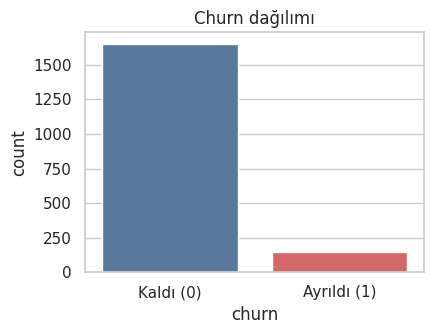

In [3]:
n, k = len(df), int(df.churn.sum())
display(Markdown(f"Müşteri: **{n}**, ayrılan: **{k}**, churn oranı: **{k/n:.2%}**, elde tutma oranı: **{1-k/n:.2%}**"))
fig, ax = plt.subplots(figsize=(4.5, 3.5))
sns.countplot(data=df, x="churn", palette=["#4c78a8", "#e45756"], ax=ax); ax.set_xticklabels(["Kaldı (0)", "Ayrıldı (1)"]); ax.set_title("Churn dağılımı")
plt.tight_layout(); plt.show()

## 4.2 Sayısal değişkenlerin dağılımı (histogram)
Histogram bir değişkenin hangi aralıkta yoğunlaştığını gösterir. Çarpıklık/aykırı değer var mı diye bakarız.

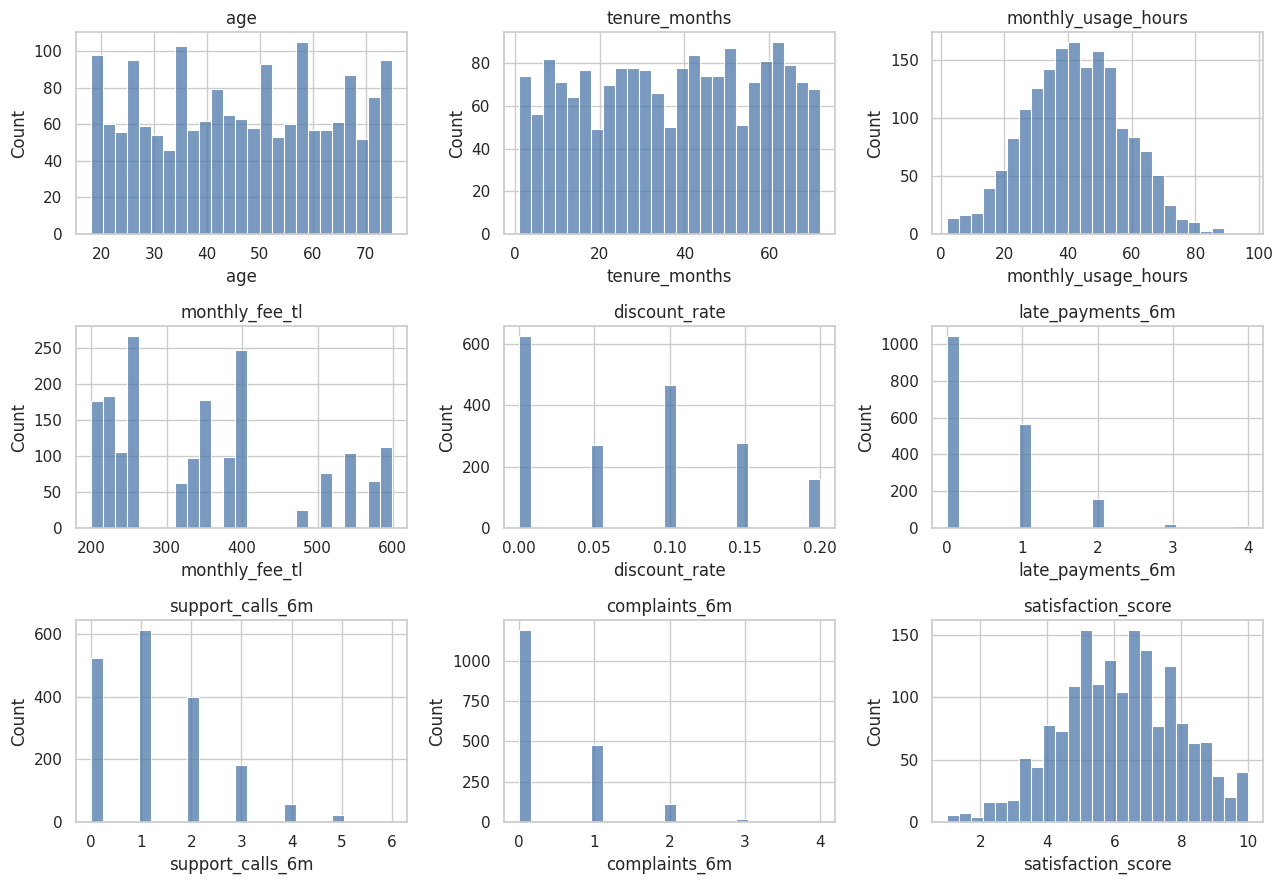

In [4]:
num_cols = C.NUMERIC_COLS
fig, axes = plt.subplots(3, 3, figsize=(13, 9))
for ax, col in zip(axes.ravel(), num_cols):
    sns.histplot(df[col].dropna(), bins=25, ax=ax, color="#4c78a8"); ax.set_title(col)
plt.tight_layout(); plt.show()

**Okuma:** `monthly_fee_tl` üç plan fiyatından türediği için *kümeli* (ayrık tepeler). Sayaç değişkenleri (gecikme, destek, şikâyet) sağa çarpık: çoğu müşteri 0-1.

## 4.3 Ayrılan vs ayrılmayan: sayısal değişkenler (boxplot)
Boxplot: medyan, çeyrekler ve IQR dışındaki noktalar. **Aykırı görünen her değer hata değildir** — 6 destek araması nadir ama gerçek olabilir.

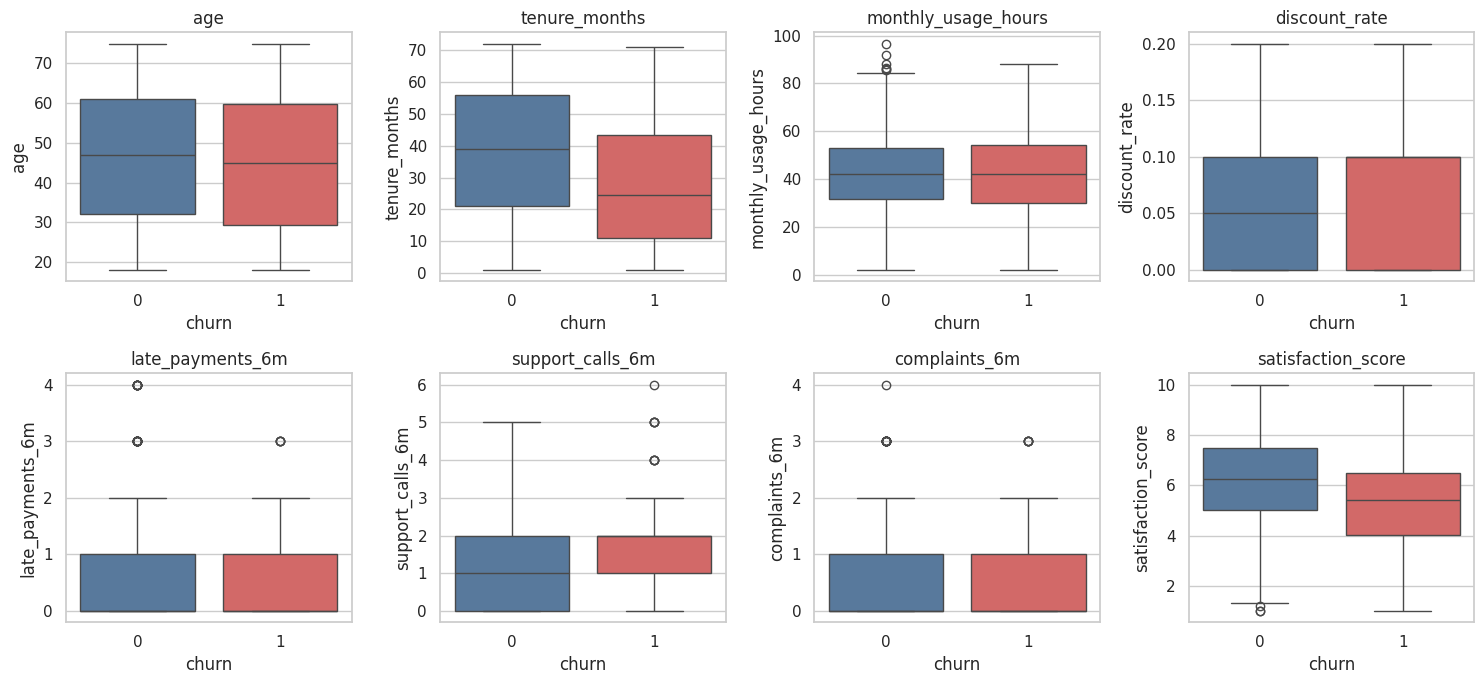

In [5]:
fig, axes = plt.subplots(2, 4, figsize=(15, 7))
for ax, col in zip(axes.ravel(), [c for c in num_cols if c != "monthly_fee_tl"]):
    sns.boxplot(data=df, x="churn", y=col, ax=ax, palette=["#4c78a8", "#e45756"]); ax.set_title(col); ax.set_xlabel("churn")
plt.tight_layout(); plt.show()

In [6]:
display(df.groupby("churn")[["tenure_months", "satisfaction_score", "complaints_6m", "support_calls_6m", "late_payments_6m", "monthly_usage_hours", "age"]].agg(["mean", "median"]).round(2).T)

churn                           0      1
tenure_months       mean   37.960 28.360
                    median 39.000 24.500
satisfaction_score  mean    6.220  5.370
                    median  6.250  5.400
complaints_6m       mean    0.400  0.660
                    median  0.000  0.000
support_calls_6m    mean    1.260  1.600
                    median  1.000  2.000
late_payments_6m    mean    0.540  0.610
                    median  0.000  0.000
monthly_usage_hours mean   42.360 42.460
                    median 42.100 42.250
age                 mean   46.760 45.660
                    median 47.000 45.000

**Okuma:** Ayrılanlar daha **kısa süreli aboneler**, memnuniyetleri **daha düşük**, şikâyet/destek sayıları **daha yüksek**. Kullanım saati ve yaş neredeyse ayırt edici değil.

## 4.4 Kategorik değişkenlerde churn oranı — **örneklem büyüklüğüyle birlikte!**
Bir segmentte %20 churn görmek, o segmentte 10 müşteri varsa anlamsızdır. Bu yüzden her çubuğun yanına **%95 Wilson güven aralığı** koyuyoruz.

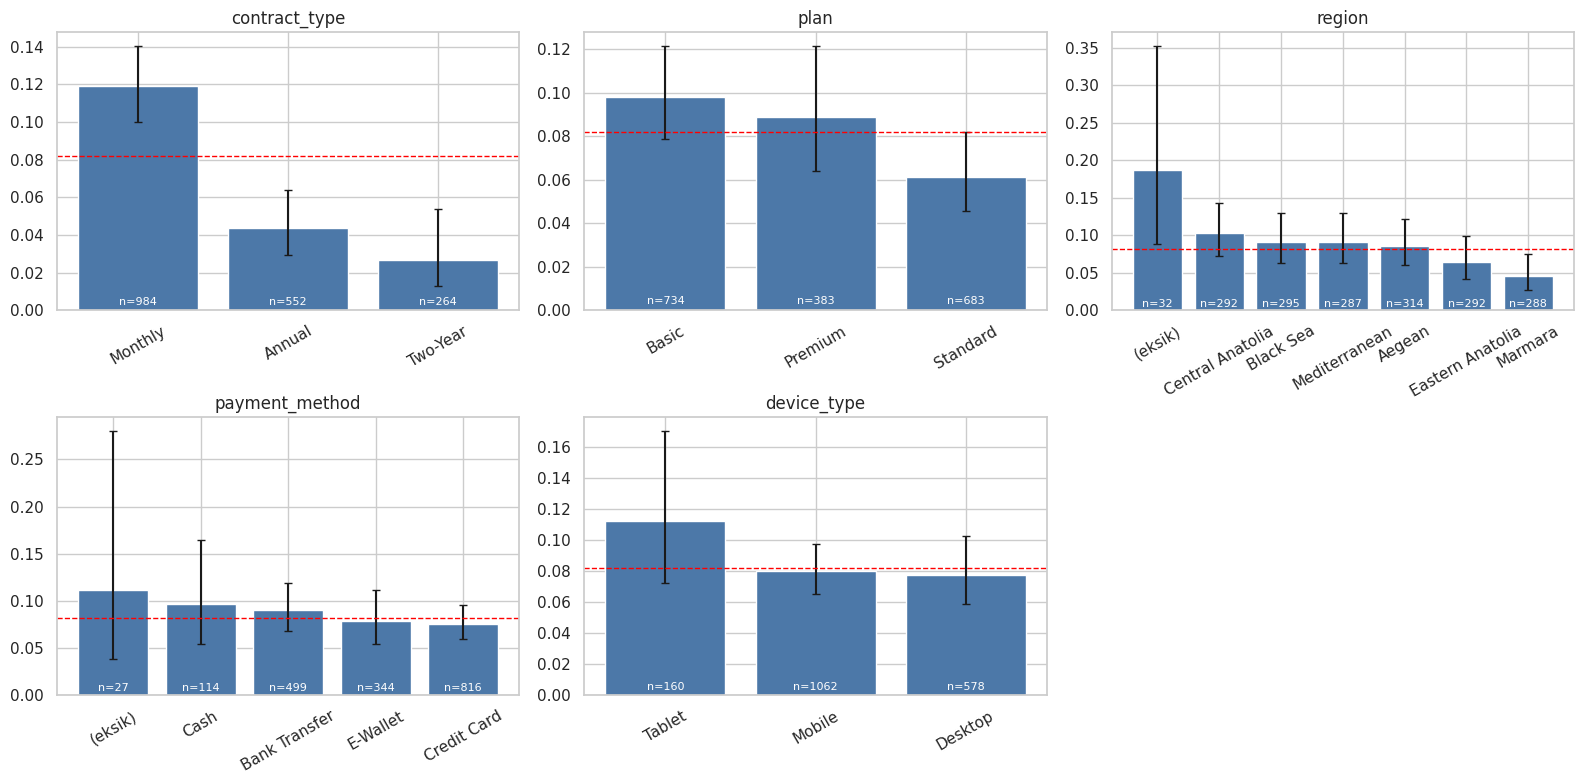

In [7]:
from statsmodels.stats.proportion import proportion_confint

def segment_table(df, col):
    g = df.groupby(col, dropna=False)["churn"].agg(["size", "sum"]).rename(columns={"size": "musteri", "sum": "ayrilan"})
    g["churn_orani"] = g["ayrilan"] / g["musteri"]
    ci = [proportion_confint(a, n, method="wilson") for a, n in zip(g["ayrilan"], g["musteri"])]
    g["ci_low"], g["ci_high"] = [c[0] for c in ci], [c[1] for c in ci]
    return g.reset_index().rename(columns={col: "segment"}).assign(degisken=col)

def plot_segments(col, ax):
    t = segment_table(df.assign(**{col: df[col].fillna("(eksik)")}), col).sort_values("churn_orani", ascending=False)
    ax.bar(t["segment"].astype(str), t["churn_orani"], color="#4c78a8")
    ax.errorbar(t["segment"].astype(str), t["churn_orani"], yerr=[t["churn_orani"] - t["ci_low"], t["ci_high"] - t["churn_orani"]], fmt="none", color="k", capsize=3)
    for i, (r, n) in enumerate(zip(t["churn_orani"], t["musteri"])): ax.text(i, 0.002, f"n={n}", ha="center", va="bottom", color="white", fontsize=8)
    ax.axhline(df.churn.mean(), color="red", ls="--", lw=1); ax.set_title(f"{col}"); ax.tick_params(axis="x", rotation=30)

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, col in zip(axes.ravel(), ["contract_type", "plan", "region", "payment_method", "device_type"]): plot_segments(col, ax)
axes.ravel()[-1].axis("off"); plt.tight_layout(); plt.show()

**Okuma:**
* **Sözleşme türü en güçlü ayırıcı:** Aylık sözleşmelerde churn çok yüksek, yıllık/iki yıllıkta çok düşük (güven aralıkları ayrışıyor).
* **Plan:** Standard daha düşük; Basic/Premium yüksek (aralıklar kısmen örtüşüyor → dikkatli ol).
* **Bölge:** Marmara düşük görünüyor ama aralıklar geniş; ayrıca bölge etkisi *sözleşme dağılımından* kaynaklanıyor olabilir (aşağıda kontrol).
* **Ödeme yöntemi ve cihaz:** belirgin bir fark yok.
* Kırmızı kesikli çizgi genel churn oranıdır.

## 4.5 Abonelik süresi ve memnuniyet: eğilim

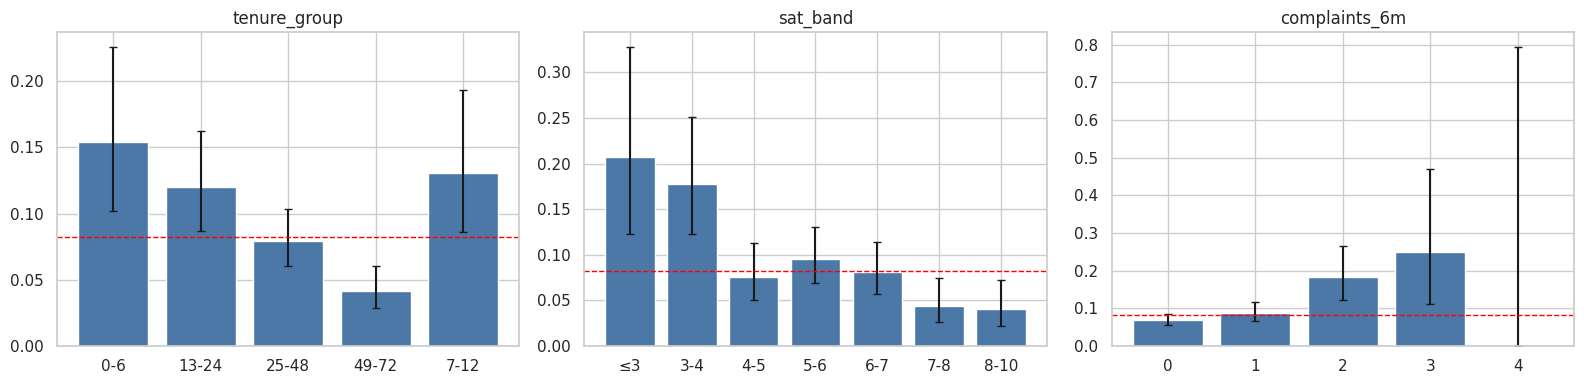

In [8]:
df["tenure_group"] = pd.cut(df.tenure_months, [0, 6, 12, 24, 48, 72], labels=["0-6", "7-12", "13-24", "25-48", "49-72"])
df["sat_band"] = pd.cut(df.satisfaction_score, [0, 3, 4, 5, 6, 7, 8, 10], labels=["≤3", "3-4", "4-5", "5-6", "6-7", "7-8", "8-10"])
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ["tenure_group", "sat_band", "complaints_6m"]):
    t = segment_table(df.assign(**{col: df[col].astype(str)}), col)
    t = t.sort_values("segment") if col != "sat_band" else t.set_index("segment").loc[["≤3", "3-4", "4-5", "5-6", "6-7", "7-8", "8-10"]].reset_index()
    ax.bar(t["segment"], t["churn_orani"], color="#4c78a8")
    ax.errorbar(t["segment"], t["churn_orani"], yerr=[t["churn_orani"] - t["ci_low"], t["ci_high"] - t["churn_orani"]], fmt="none", color="k", capsize=3)
    ax.axhline(df.churn.mean(), color="red", ls="--", lw=1); ax.set_title(col)
plt.tight_layout(); plt.show()

**Okuma:** Abonelik süresi arttıkça churn düşüyor (yeni müşteri riski). Memnuniyet düştükçe churn artıyor. Şikâyet sayısı arttıkça artıyor (3+ şikâyette örnek az, aralıklar geniş).

## 4.6 Karıştırıcı (confounding) kontrolü: bölge etkisi gerçek mi?
Marmara'da churn düşük. Ama belki Marmara'da sadece daha fazla yıllık sözleşmeli müşteri var? Sözleşme türünü sabitleyip bölgeye bakalım.

In [9]:
display(pd.crosstab(df.region, df.contract_type, normalize="index").round(3))
display(df.pivot_table(index="region", columns="contract_type", values="churn", aggfunc="mean").round(3))

contract_type,Annual,Monthly,Two-Year
region,,,
Aegean,0.312,0.532,0.156
Black Sea,0.302,0.586,0.112
Central Anatolia,0.271,0.551,0.178
Eastern Anatolia,0.315,0.548,0.137
Marmara,0.354,0.535,0.111
Mediterranean,0.268,0.547,0.185


contract_type,Annual,Monthly,Two-Year
region,,,
Aegean,0.061,0.114,0.041
Black Sea,0.056,0.121,0.030
Central Anatolia,0.038,0.143,0.077
Eastern Anatolia,0.033,0.100,0.000
Marmara,0.020,0.071,0.000
Mediterranean,0.039,0.146,0.000


**Okuma:** Sözleşme dağılımı bölgeler arasında benzer (aylık %53-59); ayrıca Marmara aylık sözleşmelilerde de diğer bölgelerden düşük (%7 civarı). Yani Marmara'nın düşük oranı sözleşme dağılımıyla açıklanmıyor görünüyor. Ama her hücrede müşteri sayısı küçük olduğundan, bu farkın **şans olup olmadığını** Notebook 05'te istatistiksel testle sorgulayacağız.

## 4.7 Korelasyon matrisi
Korelasyon −1 ile +1 arasındadır ve yalnızca **doğrusal** ilişkiyi ölçer. `churn` ikili olduğu için bu "point-biserial" korelasyondur.

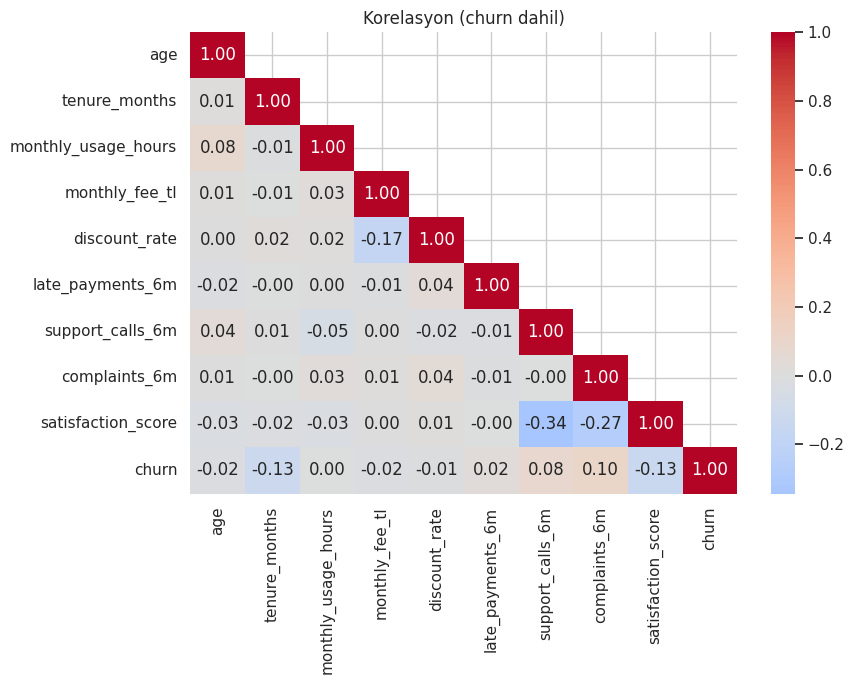

,churn ile korelasyon
satisfaction_score,-0.134
tenure_months,-0.128
monthly_fee_tl,-0.018
age,-0.018
discount_rate,-0.011
monthly_usage_hours,0.002
late_payments_6m,0.024
support_calls_6m,0.082
complaints_6m,0.105


In [10]:
corr = df[C.NUMERIC_COLS + ["churn"]].corr()
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax, mask=np.triu(np.ones_like(corr, dtype=bool), 1)); ax.set_title("Korelasyon (churn dahil)")
plt.tight_layout(); plt.show()
display(corr["churn"].drop("churn").sort_values().to_frame("churn ile korelasyon"))

**Okuma:** Tüm korelasyonlar küçük (|r| ≲ 0,14). Bu, **churn'ün tek bir değişkenle açıklanamayacağını** ve modelden mucize beklememek gerektiğini söyler. `monthly_fee_tl` ile `discount_rate` arasındaki ilişki plan/indirim yapısından gelir.

## 4.8 Eksik olmak bilgi taşıyor mu? (missing-not-at-random kontrolü)
Bir değer *neden* eksik? Eksik olan müşteriler farklı mı davranıyor?

In [11]:
rows = []
for col in ["age", "region", "monthly_usage_hours", "payment_method", "satisfaction_score"]:
    m = df[col].isna()
    rows.append({"sütun": col, "eksik_adet": int(m.sum()), "churn_eksik": df.loc[m, "churn"].mean(), "churn_dolu": df.loc[~m, "churn"].mean()})
display(pd.DataFrame(rows))

,sütun,eksik_adet,churn_eksik,churn_dolu
0,age,50,0.120,0.081
1,region,32,0.188,0.080
2,monthly_usage_hours,67,0.119,0.081
3,payment_method,27,0.111,0.082
4,satisfaction_score,82,0.073,0.083


**Okuma:** `region` eksik olanlarda churn %18,8 görünüyor (n=32, yani ~6 kişi): dikkat çekici ama örnek çok küçük. İstatistiksel olarak anlamlı mı? → Notebook 05.

## 4.9 EDA sonuç özeti
1. Dengesiz hedef (~%8). Accuracy kullanılmayacak.
2. En güçlü sinyaller: **sözleşme türü, abonelik süresi, memnuniyet, şikâyet/destek**.
3. Zayıf/ayırt edici olmayan: cihaz, ödeme yöntemi, yaş, kullanım saati.
4. Tek tek ilişkiler zayıf → makul model başarısı **orta düzeyde** olacak (ROC-AUC ≈ 0,7-0,75). Çok yüksek bir skor görürsek şüphelenmeliyiz (sızıntı?).